In [40]:
import numpy as np
import time
import matplotlib.pyplot as plt

ALPHA = 0.1
GAMMA = 0.8
EPSILON = 0.0

In [41]:
class GridWorld():
    def __init__(self, size=5, pits = [[1,3],[2,1]], goal=None):
        self.size = size
        self.pos = [0,0]
        self.next_pos = [0,0]
        self.step_reward = -1
        self.pit_reward = -10
        self.goal_reward = 20

        self.goal_counter = 0
        self.pit_counter = 0



        self.goal = [size-1,size-1]
        self.pits = pits
        self.reset()
        self.av = np.zeros((size,size,4))

        

    def reset(self):
        self.pos = (0,0)
        return self.pos

    def trial_left(self):
       self.next_pos = [self.pos[0],max(0,self.pos[1]-1)]
       self.av[self.pos[0],self.pos[1]] += ALPHA *  (self.step_reward + (GAMMA * self.av[(self.next_pos[0],self.next_pos[1])].max()))

       self.pos = self.next_pos
       print(self.av[self.pos[0],self.pos[1],0])
       print(self.next_pos)

    def trial_right(self):
           self.next_pos = [self.pos[0],min(self.size-1,self.pos[1]+1)]
           self.av[self.pos[0],self.pos[1]] += ALPHA *  (self.step_reward + (GAMMA * self.av[(self.next_pos[0],self.next_pos[1])].max()))
    
           self.pos = self.next_pos
           print(self.av[self.pos[0],self.pos[1],0])
           print(self.next_pos)
        


    def step(self):
        if (np.random.rand() < EPSILON):
            max_idx = np.random.randint(0,4)
        else:
            max_idx = np.argmax(self.av[self.pos[0],self.pos[1]])

        match max_idx:
            case 0: #LEFT
                print("LEFT")
                self.next_pos = [self.pos[0],max(0,self.pos[1]-1)]
            case 1: #UP
                print("UP")
                self.next_pos = [max(0,self.pos[0]-1), self.pos[1]]
            case 2: #RIGHT
                print("RIGHT")
                self.next_pos = [self.pos[0],min(self.size-1,self.pos[1]+1)]
            case 3: #DOWN
                print("DOWN")
                self.next_pos = [min(self.size-1,self.pos[0]+1), self.pos[1]]
            case _:
                print("idk if this could be triggered, bravo")

        # reward = self.step_reward
        if(self.next_pos in self.pits):
            print(f"I fell in pit {self.next_pos} \n\n")
            self.av[self.pos[0],self.pos[1],max_idx] += ALPHA *  (self.pit_reward + (GAMMA * self.av[(self.next_pos[0],self.next_pos[1])].max()) - self.av[self.pos[0],self.pos[1],max_idx])
            self.pos = [0,0]
            self.pit_counter += 1
            return
        elif(self.next_pos == self.goal):
            print("I reached goal")
            self.goal_counter += 1
            self.av[self.pos[0],self.pos[1],max_idx] += ALPHA *  (self.goal_reward + (GAMMA * self.av[(self.next_pos[0],self.next_pos[1])].max()) - self.av[self.pos[0],self.pos[1],max_idx])
            self.pos = [0,0]
            return
            
        self.av[self.pos[0],self.pos[1],max_idx] += ALPHA *  (self.step_reward + (GAMMA * self.av[(self.next_pos[0],self.next_pos[1])].max()) - self.av[self.pos[0],self.pos[1],max_idx])

        self.pos = self.next_pos
        print(self.av[self.pos[0],self.pos[1],0])
        print(self.next_pos)
        print("\n")


In [42]:
env = GridWorld(size=5)

steps = 1600

episodes = set()

start = time.time()

for i in range(steps):
    env.step()
    episodes.add((env.goal_counter,(env.goal_counter+env.pit_counter)))

end = time.time()

print(f"Time taken : {end-start}")

print(f"reached {env.goal_counter} goals in {steps} steps and {env.pit_counter +env.goal_counter} episodes")


LEFT
-0.1
[0, 0]


UP
-0.1
[0, 0]


RIGHT
0.0
[0, 1]


LEFT
-0.1
[0, 0]


DOWN
0.0
[1, 0]


LEFT
-0.1
[1, 0]


UP
-0.1
[0, 0]


LEFT
-0.198
[0, 0]


UP
-0.198
[0, 0]


RIGHT
-0.1
[0, 1]


UP
-0.1
[0, 1]


RIGHT
0.0
[0, 2]


LEFT
-0.1
[0, 1]


DOWN
0.0
[1, 1]


LEFT
-0.1
[1, 0]


RIGHT
-0.1
[1, 1]


UP
-0.1
[0, 1]


LEFT
-0.198
[0, 0]


DOWN
-0.1
[1, 0]


DOWN
0.0
[2, 0]


LEFT
-0.1
[2, 0]


UP
-0.1
[1, 0]


LEFT
-0.198
[1, 0]


RIGHT
-0.1
[1, 1]


RIGHT
0.0
[1, 2]


LEFT
-0.1
[1, 1]


DOWN
I fell in pit [2, 1] 


RIGHT
-0.198
[0, 1]


UP
-0.198
[0, 1]


RIGHT
-0.1
[0, 2]


UP
-0.1
[0, 2]


RIGHT
0.0
[0, 3]


LEFT
-0.1
[0, 2]


DOWN
-0.1
[1, 2]


UP
-0.1
[0, 2]


LEFT
-0.198
[0, 1]


DOWN
-0.1
[1, 1]


LEFT
-0.198
[1, 0]


DOWN
-0.1
[2, 0]


RIGHT
I fell in pit [2, 1] 


DOWN
-0.198
[1, 0]


UP
-0.198
[0, 0]


LEFT
-0.29404
[0, 0]


UP
-0.29404
[0, 0]


RIGHT
-0.198
[0, 1]


RIGHT
-0.198
[0, 2]


UP
-0.198
[0, 2]


RIGHT
-0.1
[0, 3]


UP
-0.1
[0, 3]


RIGHT
0.0
[0, 4]


LEFT
-0.1
[0, 3]

In [ ]:
episodes

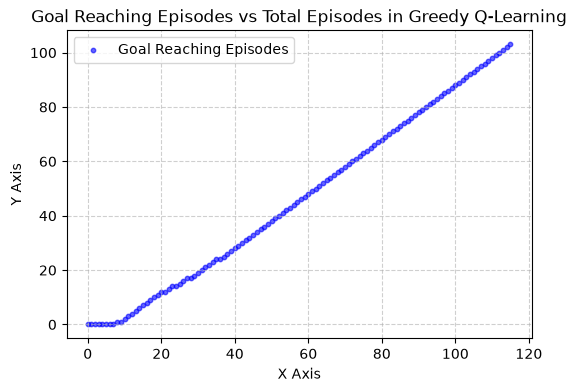

In [44]:
y,x = zip(*episodes)

plt.figure(figsize=(6,4))

plt.scatter(x,y,color = 'blue', marker='o', s=10, alpha=0.6 ,label='Goal Reaching Episodes')
# plt.plot(x, y, marker="o", color='red')

plt.title('Goal Reaching Episodes vs Total Episodes in Greedy Q-Learning')
plt.xlabel('X Axis')
plt.ylabel('Y Axis')
# plt.ylim(0,5000)
# plt.xlim(0,5000)
plt.grid(True, linestyle='--', alpha = 0.6)
plt.legend()

plt.show()